In [13]:
import sys
import os
import numpy as np
import pandas as pd


sys.path.append(os.path.join(os.getcwd(), 'import'))

# noinspection PyUnresolvedReferences
from utils import read_utils
# noinspection PyUnresolvedReferences
from utils import plot_utils
# noinspection PyUnresolvedReferences
from utils import train_utils
# noinspection PyUnresolvedReferences
from utils import artificializer

# noinspection PyUnresolvedReferences
from models import hgm
# noinspection PyUnresolvedReferences
from models import bom

In [14]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(artificializer)
importlib.reload(bom)
importlib.reload(hgm)

<module 'models.hgm' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/Work/ZimmerLab/MSc_Thesis/Workspace/hobe/worm-2025-fieseler/import/models/hgm.py'>

In [15]:
selection_n = ['DD01', 'VB02', 'AVAR', 'ALA']  # 'DB01',
selection_bhl = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

read_ids = list(range(0, 33+1))
# read_ids = [0, 12, 14, 23, 29, 32]
# read_ids = [14]
plot_id = 14

dims_generation = 2
weights = (0.1, -0.25)

In [16]:
# read
path = os.path.join(read_utils.get_data_path(), 'worm-2025-fieseler', 'exported_data_gcamp')
(file_ids_gcamp, filenames_gcamp,
 traces_gcamp,
 continuous_behaviors_gcamp,
 discrete_states_gcamp, eigenworms_gcamp,
 kymographs_gcamp) = read_utils.get_data(path, read_ids)

# clear nan values
for i in range(len(file_ids_gcamp)):
	mask = eigenworms_gcamp[i].notna().all(axis=1)

	traces_gcamp[i] = traces_gcamp[i][mask]
	#continuous_behaviors_gcamp[i] = continuous_behaviors_gcamp[i][mask]
	eigenworms_gcamp[i] = eigenworms_gcamp[i][mask]
	discrete_states_gcamp[i] = discrete_states_gcamp[i][mask]

	#kymographs_gcamp[i] = kymographs_gcamp[i][mask]
	#filenames_gcamp[i] = filenames_gcamp[i][mask]

# remove unused discrete state labels
discrete_states_gcamp = [ds[selection_bhl] for ds in discrete_states_gcamp]

# naive ID unknown neurons
for i in range(len(file_ids_gcamp)):
	traces_gcamp[i].columns = pd.Index([
		f'{file_ids_gcamp[i]:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces_gcamp[i].columns, traces_gcamp[i].columns == ''))
	])

In [17]:
# generate

file_ids_art = list()
filenames_art = list()

discrete_states_art = list()
eigenworms_art = list()

modes_art = list()
traces_reconstructed_art = list()
traces_residual_art = list()
traces_art = list()

for i in range(len(file_ids_gcamp)):
	(filename_art,
	 neural_modes_art_,
	 traces_reconstructed_art_,
	 traces_residual_art_,
	 traces_art_,
	 params_art_,
	 params_cca_art_) = artificializer.artificialize(weights, hgm,
													 filenames_gcamp[i],
													 traces_gcamp[i].columns,
													 eigenworms_gcamp[i],
													 discrete_states_gcamp[i],
													 n_dimensions=dims_generation)
	filenames_art.append(filename_art)

	modes_art.append(neural_modes_art_)
	traces_reconstructed_art.append(traces_reconstructed_art_)
	traces_residual_art.append(traces_residual_art_)
	traces_art.append(traces_art_)

	file_ids_art.append(file_ids_gcamp[i])

	discrete_states_art.append(discrete_states_gcamp[i].copy())
	eigenworms_art.append(eigenworms_gcamp[i].copy())

In [18]:
# plot_utils.plot_traces(f'[{filenames_gcamp[file_ids_gcamp.index(plot_id)]}] traces gcamp',
# 					   discrete_states_gcamp[file_ids_gcamp.index(plot_id)][['REV']],
# 					   traces_gcamp[file_ids_gcamp.index(plot_id)][selection_n],
# 					   n_plots=len(selection_n), plots_per_row=1, ylimits=None)

In [19]:
# plot_utils.plot_traces(f'[{filenames_gcamp[file_ids_gcamp.index(plot_id)]}] eigenworms gcamp',
# 					   discrete_states_gcamp[file_ids_gcamp.index(plot_id)][['REV']],
# 					   eigenworms_gcamp[file_ids_gcamp.index(plot_id)],
# 					   plots_per_row=1, ylimits=None)

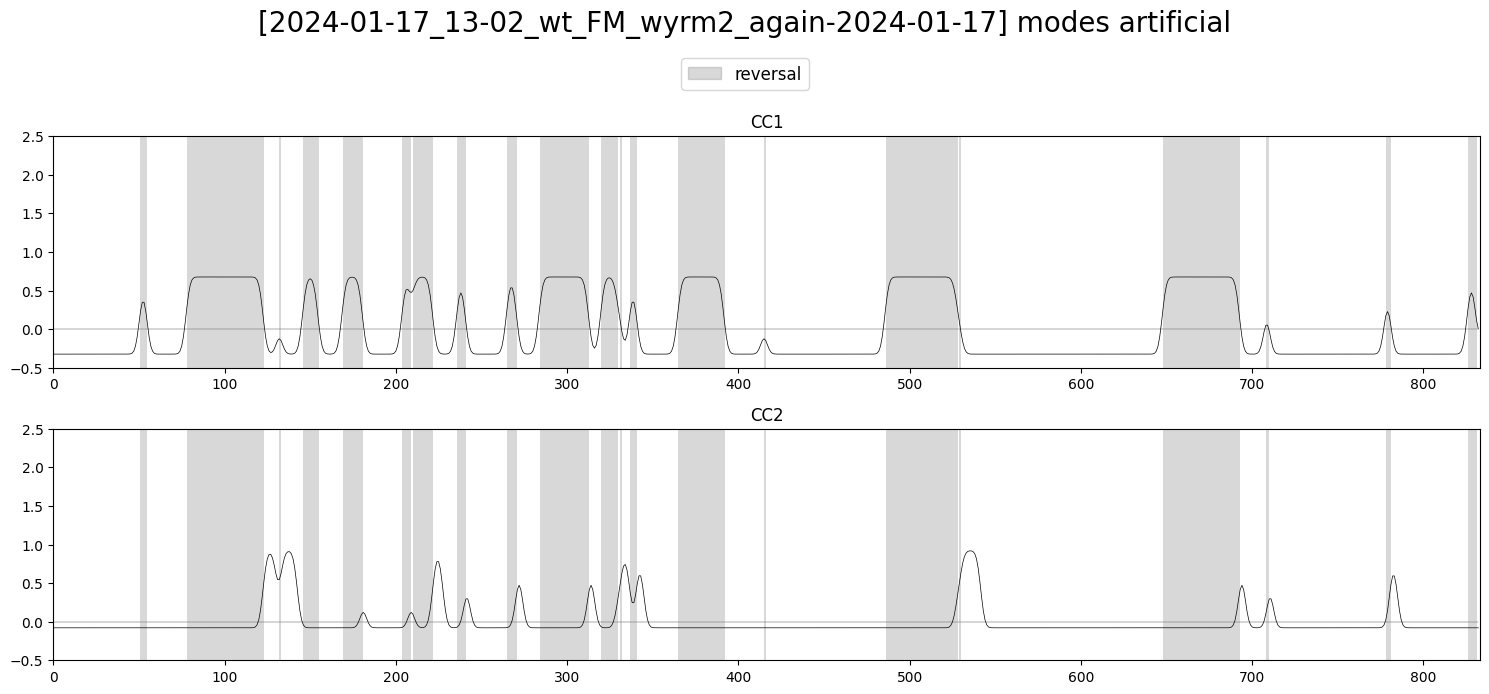

In [20]:
plot_utils.plot_traces(f'[{filenames_art[file_ids_gcamp.index(plot_id)]}] modes artificial',
					   discrete_states_art[file_ids_gcamp.index(plot_id)][['REV']],
					   modes_art[file_ids_gcamp.index(plot_id)],
					   plots_per_row=1, ylimits=(-0.5, 2.5))

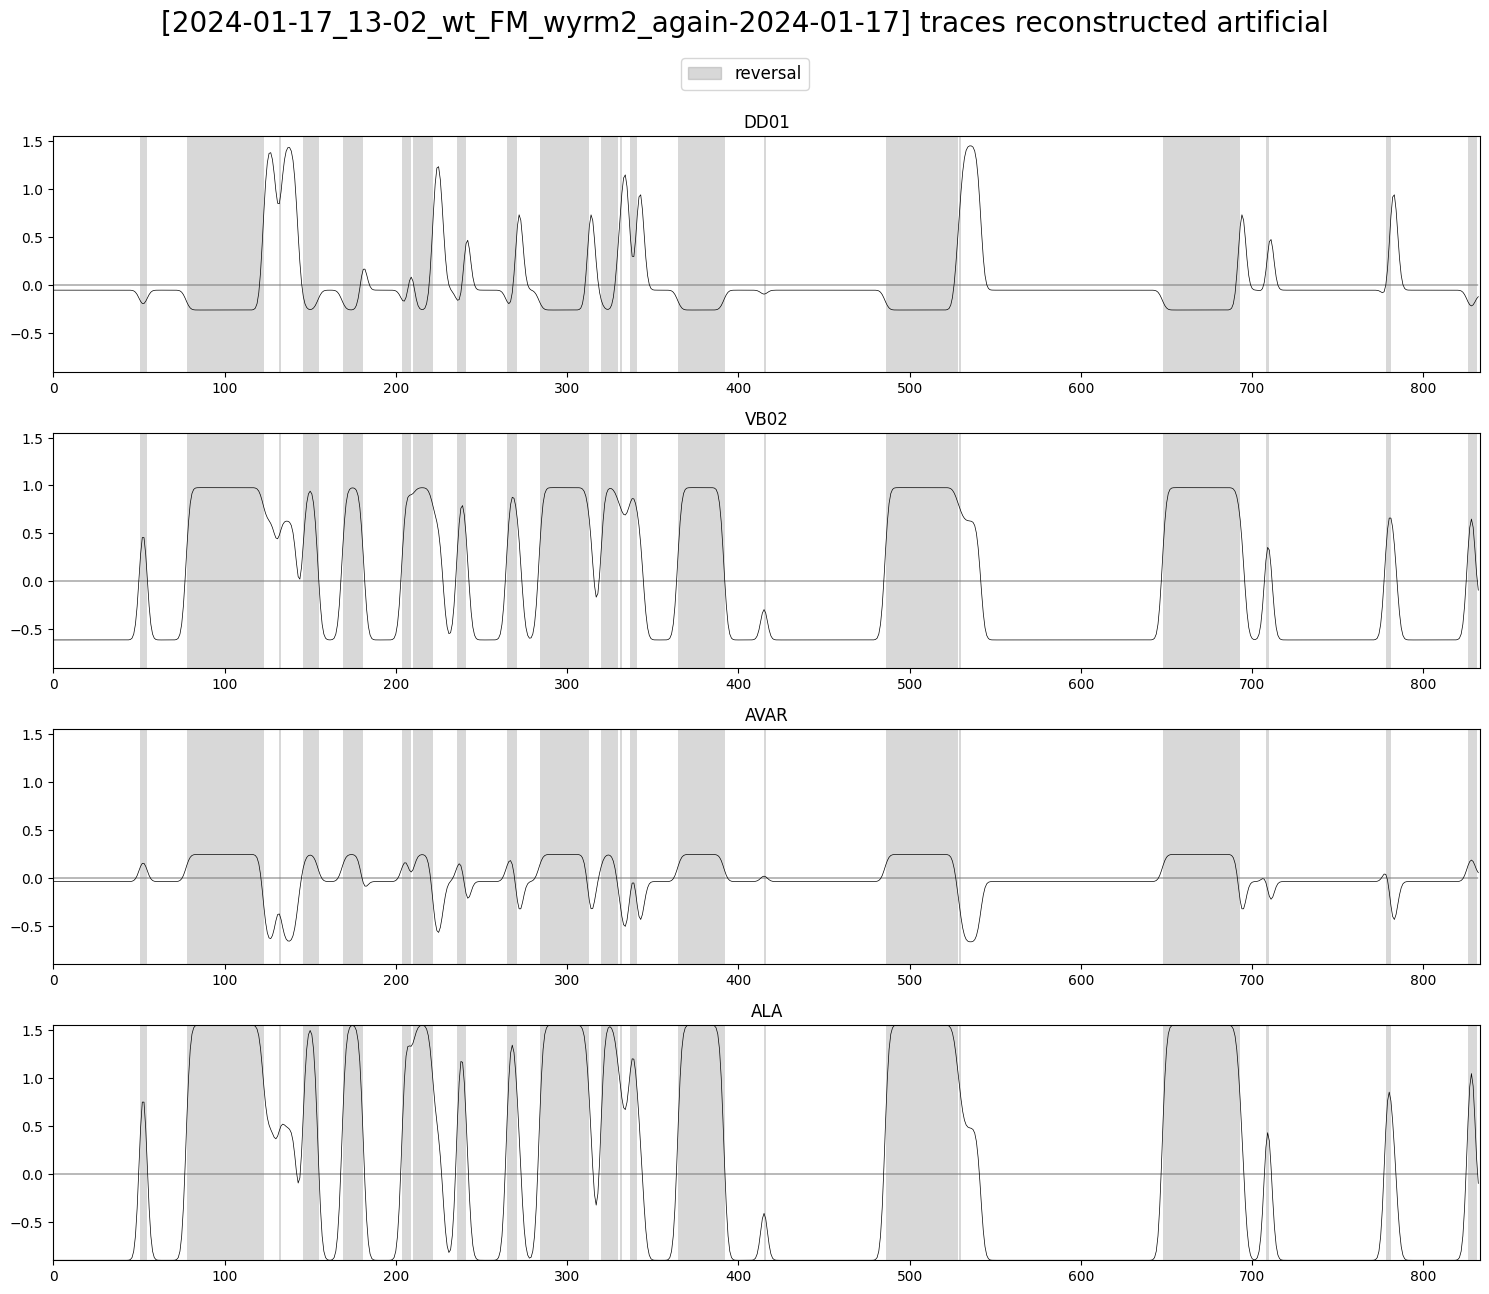

In [21]:
plot_utils.plot_traces(f'[{filenames_art[file_ids_gcamp.index(plot_id)]}] traces reconstructed artificial',
					   discrete_states_art[file_ids_gcamp.index(plot_id)][['REV']],
					   traces_reconstructed_art[file_ids_gcamp.index(plot_id)][selection_n],
					   plots_per_row=1, ylimits=None)

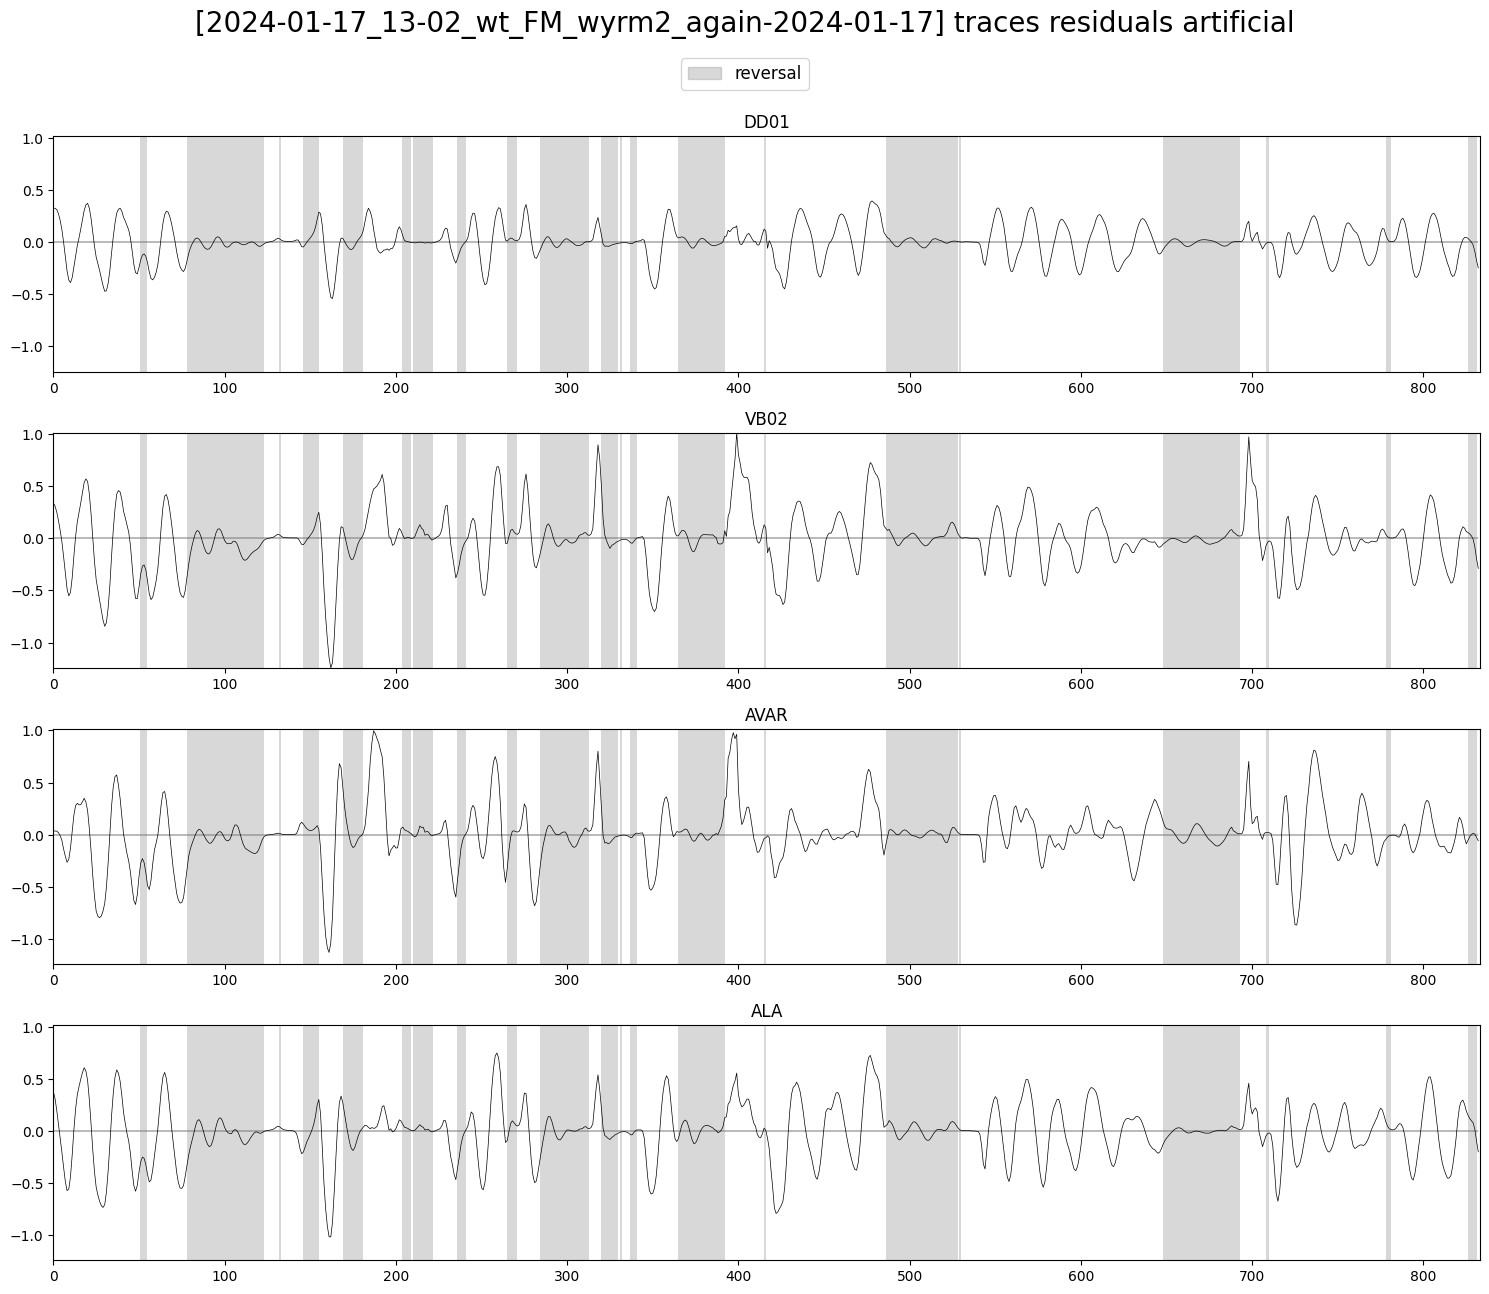

In [22]:
plot_utils.plot_traces(f'[{filenames_art[file_ids_gcamp.index(plot_id)]}] traces residuals artificial',
					   discrete_states_art[file_ids_gcamp.index(plot_id)][['REV']],
					   traces_residual_art[file_ids_gcamp.index(plot_id)][selection_n],
					   plots_per_row=1, ylimits=None)

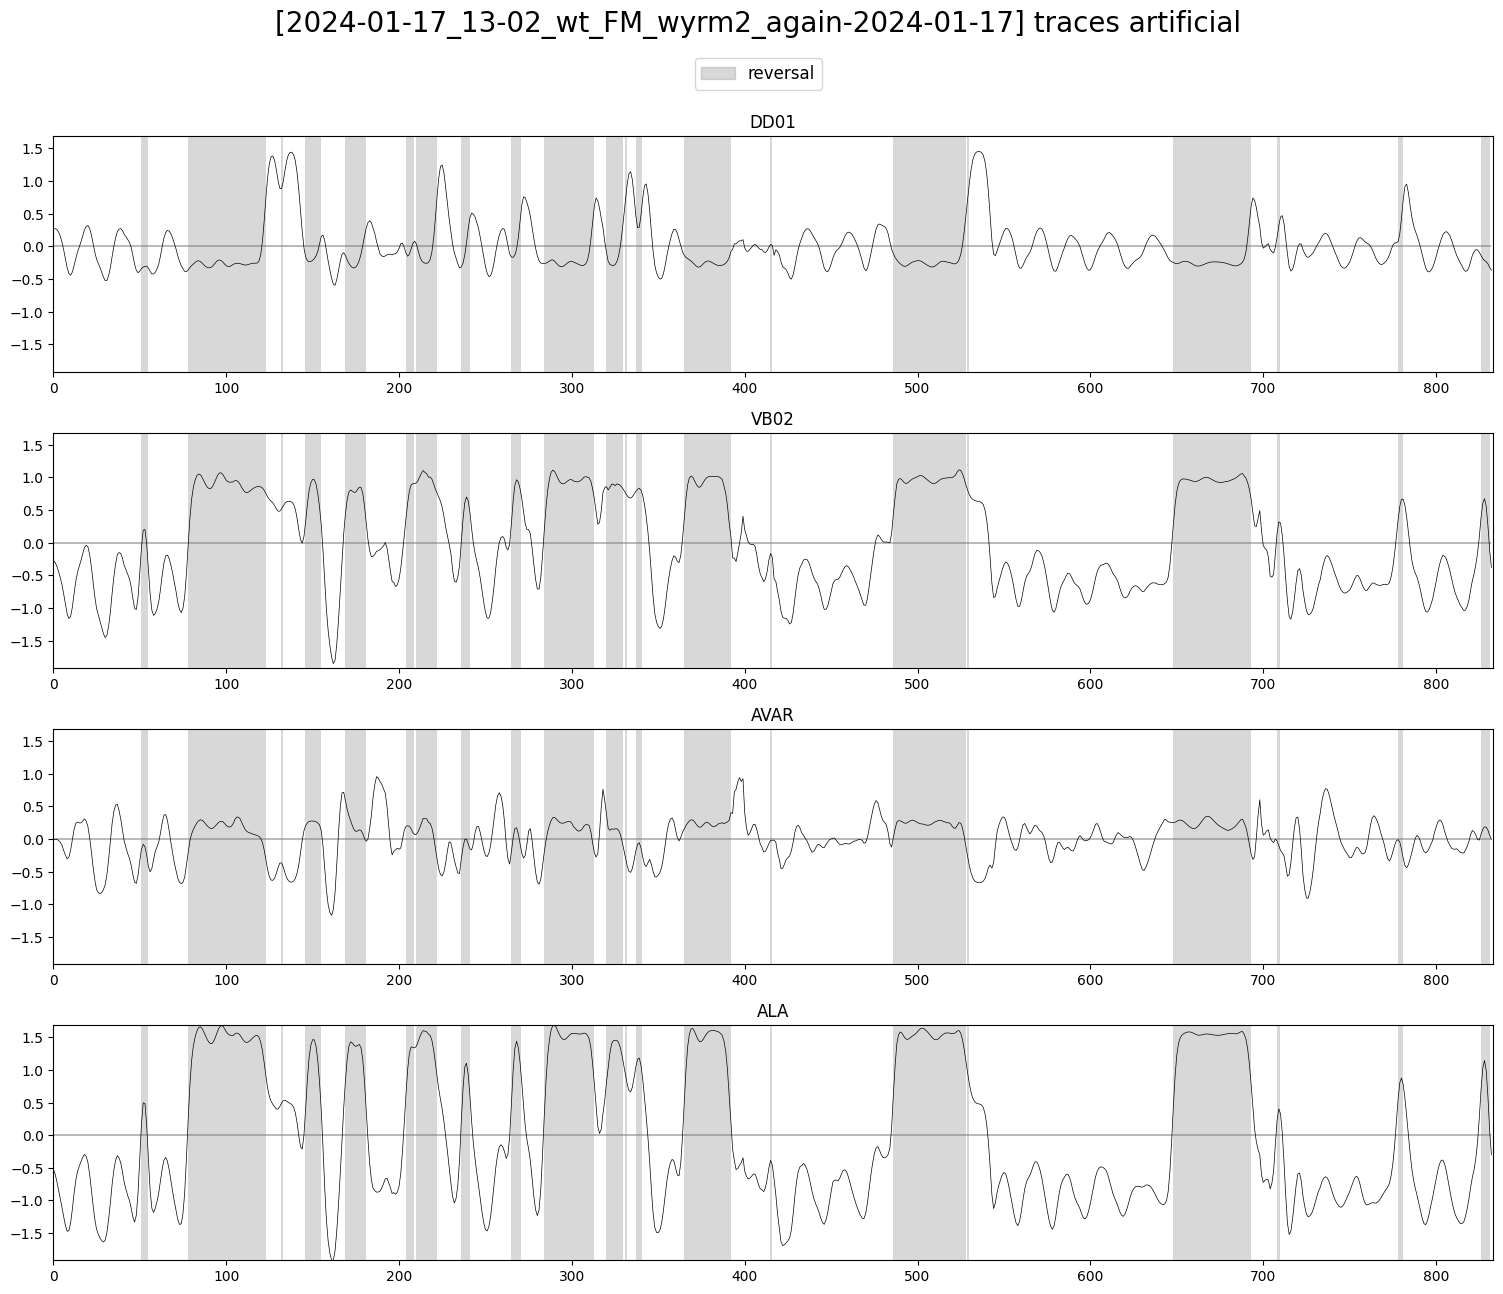

In [23]:
plot_utils.plot_traces(f'[{filenames_art[file_ids_gcamp.index(plot_id)]}] traces artificial',
					   discrete_states_art[file_ids_gcamp.index(plot_id)][['REV']],
					   traces_art[file_ids_gcamp.index(plot_id)][selection_n],
					   plots_per_row=1, ylimits=None)